# GAIA — Prévision de l'humidité du sol à 7 jours (modèle entraîné)

**Objectif :** apprendre, à partir de données réelles de Tunisie, à prédire **l'humidité du sol dans la zone des racines (7–28 cm) pour chacun des 7 prochains jours**, puis en déduire quand irriguer.

**Couverture :** 26 sites, les 24 gouvernorats de Tunisie, 2016–2024.

**Dataset :** [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), réanalyse **ERA5 / ERA5-Land** (Copernicus, ECMWF). Gratuit, sans inscription, au jour le jour depuis 1950, pour n'importe quel point.

| Variable | Rôle |
|---|---|
| Humidité du sol 0–7, 7–28, 28–100 cm (m³/m³) | **cible** (7–28 cm) et entrées |
| ET0 FAO, pluie, températures, rayonnement, vent | entrées |
| Latitude, longitude, altitude, saison | entrées |

**Modèle :** LightGBM (gradient boosting), un modèle par horizon (J+1 … J+7). Il prédit **la variation** de l'humidité par rapport à aujourd'hui.

**Évaluation honnête :**
- entraînement 2016–2020, validation 2021, **test 2022–2024** (années jamais vues) ;
- 4 sites **jamais vus** à l'entraînement (test géographique) ;
- comparaison avec la **persistance** (« dans h jours, l'humidité sera la même qu'aujourd'hui »).

> ⚠️ **Limites à annoncer :** l'humidité ERA5-Land est une *reconstruction de modèle* (~9 km), pas une mesure de terrain, et elle ne connaît pas la culture de la parcelle. Pendant l'entraînement, la météo des 7 jours suivants est la météo *observée* (prévision parfaite) ; en usage réel ce sera une *prévision*, donc l'erreur sera un peu plus grande.

In [1]:
import time, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import lightgbm as lgb
import matplotlib.pyplot as plt

DATA_DIR = Path("data");    DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

START, END = "2016-01-01", "2024-12-31"
HORIZONS = range(1, 8)
CIBLE = "sm_7_28"   # humidité du sol 7–28 cm, zone des racines
plt.rcParams["figure.figsize"] = (11, 4)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
JOURS = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]

## 1. Les sites : 26 points agricoles couvrant les 24 gouvernorats
Du Nord céréalier aux oasis du Sud, en passant par le Sahel des oliviers et le pays des jessour (Tataouine). Chaque point est placé dans une zone agricole du gouvernorat, un peu à l'intérieur des terres pour que la case ERA5-Land soit bien sur la terre. Quatre sites (un par grande zone) sont **gardés de côté** pour tester le modèle sur des lieux qu'il n'a jamais vus.

In [2]:
SITES = [
    # id,            nom,                         lat,    lon,   zone,            test géographique
    ("beja",        "Béja",                       36.73,  9.18, "Nord",           False),
    ("jendouba",    "Jendouba",                   36.50,  8.78, "Nord",           False),
    ("bousalem",    "Bou Salem",                  36.61,  8.97, "Nord",           True),
    ("kef",         "Le Kef",                     36.17,  8.70, "Nord-Ouest",     False),
    ("siliana",     "Siliana",                    36.08,  9.37, "Nord-Ouest",     False),
    ("zaghouan",    "Zaghouan",                   36.40, 10.14, "Nord-Est",       False),
    ("mateur",      "Mateur",                     37.04,  9.66, "Nord",           False),
    ("capbon",      "Menzel Bouzelfa (Cap Bon)",  36.68, 10.58, "Nord-Est",       False),
    ("kairouan",    "Kairouan",                   35.68, 10.10, "Centre",         False),
    ("sbeitla",     "Sbeitla",                    35.23,  9.13, "Centre-Ouest",   True),
    ("sidibouzid",  "Sidi Bouzid",                35.04,  9.48, "Centre",         False),
    ("kasserine",   "Kasserine",                  35.17,  8.83, "Centre-Ouest",   False),
    ("sfax",        "Agareb (Sfax)",              34.74, 10.52, "Sahel",          False),
    ("msaken",      "Msaken (Sahel)",             35.73, 10.58, "Sahel",          True),
    ("gafsa",       "Gafsa",                      34.42,  8.78, "Sud-Ouest",      False),
    ("medenine",    "Médenine",                   33.35, 10.50, "Sud-Est",        False),
    ("kebili",      "Kébili",                     33.70,  8.97, "Sud (oasis)",    True),
    ("tozeur",      "Tozeur",                     33.92,  8.13, "Sud (oasis)",    False),
    ("tunis",       "Tunis (Sijoumi)",            36.78, 10.08, "Grand Tunis",    False),
    ("ariana",      "Kalâat el-Andalous (Ariana)",37.02, 10.08, "Grand Tunis",    False),
    ("benarous",    "Mornag (Ben Arous)",         36.68, 10.29, "Grand Tunis",    False),
    ("manouba",     "Tebourba (Manouba)",         36.83,  9.84, "Nord (Medjerda)",False),
    ("monastir",    "Jemmal (Monastir)",          35.62, 10.76, "Sahel",          False),
    ("mahdia",      "El Jem (Mahdia)",            35.30, 10.71, "Sahel",          False),
    ("gabes",       "Chenini (oasis de Gabès)",   33.87, 10.06, "Sud-Est (oasis littorale)", False),
    ("tataouine",   "Tataouine (jessour)",        32.93, 10.45, "Sud-Est",        False),
]
SITES = pd.DataFrame(SITES, columns=["id", "nom", "lat", "lon", "zone", "test_geo"])
SITES

,id,nom,lat,lon,zone,test_geo
0,beja,Béja,36.73,9.18,Nord,False
1,jendouba,Jendouba,36.50,8.78,Nord,False
2,bousalem,Bou Salem,36.61,8.97,Nord,True
3,kef,Le Kef,36.17,8.70,Nord-Ouest,False
4,siliana,Siliana,36.08,9.37,Nord-Ouest,False
5,zaghouan,Zaghouan,36.40,10.14,Nord-Est,False
6,mateur,Mateur,37.04,9.66,Nord,False
7,capbon,Menzel Bouzelfa (Cap Bon),36.68,10.58,Nord-Est,False
8,kairouan,Kairouan,35.68,10.10,Centre,False
9,sbeitla,Sbeitla,35.23,9.13,Centre-Ouest,True


## 2. Téléchargement des données (mises en cache dans `data/`)
Une requête par site. Les fichiers sont gardés sur le disque : relancer le notebook ne retélécharge rien.

In [3]:
URL = "https://archive-api.open-meteo.com/v1/archive"
DAILY  = ["et0_fao_evapotranspiration", "precipitation_sum", "temperature_2m_max",
          "temperature_2m_min", "shortwave_radiation_sum", "wind_speed_10m_max"]
HOURLY = ["soil_moisture_0_to_7cm", "soil_moisture_7_to_28cm", "soil_moisture_28_to_100cm"]
RENOMMER = {"et0_fao_evapotranspiration": "et0", "precipitation_sum": "pluie",
            "temperature_2m_max": "tmax", "temperature_2m_min": "tmin",
            "shortwave_radiation_sum": "rayonnement", "wind_speed_10m_max": "vent",
            "soil_moisture_0_to_7cm": "sm_0_7", "soil_moisture_7_to_28cm": "sm_7_28",
            "soil_moisture_28_to_100cm": "sm_28_100"}


def appel_open_meteo(url, params):
    for essai in range(5):
        r = requests.get(url, params=params, timeout=180)
        if r.status_code == 429:                       # limite de requêtes : on patiente
            time.sleep(60 * (essai + 1)); continue
        r.raise_for_status()
        return r.json()
    raise RuntimeError("Open-Meteo refuse les requêtes (limite atteinte), réessayez plus tard.")


def json_vers_table(j):
    h = pd.DataFrame(j["hourly"])
    h["date"] = pd.to_datetime(h.pop("time")).dt.floor("D")
    h = h.groupby("date").mean()                       # moyenne journalière de l'humidité du sol
    d = pd.DataFrame(j["daily"])
    d["date"] = pd.to_datetime(d.pop("time"))
    return d.set_index("date").join(h).rename(columns=RENOMMER).reset_index()


def telecharger(site):
    f = DATA_DIR / f"{site.id}.csv"
    if f.exists():
        return pd.read_csv(f, parse_dates=["date"])
    j = appel_open_meteo(URL, dict(latitude=site.lat, longitude=site.lon, start_date=START, end_date=END,
                                   daily=",".join(DAILY), hourly=",".join(HOURLY), timezone="Africa/Tunis"))
    df = json_vers_table(j)
    df["altitude"] = j["elevation"]
    df.to_csv(f, index=False)
    time.sleep(2)
    return df


tables = []
for s in SITES.itertuples():
    df = telecharger(s)
    df["site"], df["lat"], df["lon"], df["test_geo"] = s.id, s.lat, s.lon, s.test_geo
    tables.append(df)
    print(f"{s.nom:28s} {len(df):5d} jours   humidité 7–28 cm moyenne = {df.sm_7_28.mean():.3f} m³/m³")

data = pd.concat(tables, ignore_index=True)
manque = data.groupby("site")[CIBLE].apply(lambda x: x.isna().mean())
sans_sol = manque[manque > 0.5].index.tolist()
if sans_sol:
    print("⚠️ Sites sans données de sol (case ERA5-Land sur la mer ?), retirés :", sans_sol)
    data = data[~data.site.isin(sans_sol)]
print("\nTotal :", len(data), "lignes,", data.site.nunique(), "sites")

Béja                          3288 jours   humidité 7–28 cm moyenne = 0.323 m³/m³
Jendouba                      3288 jours   humidité 7–28 cm moyenne = 0.189 m³/m³
Bou Salem                     3288 jours   humidité 7–28 cm moyenne = 0.186 m³/m³
Le Kef                        3288 jours   humidité 7–28 cm moyenne = 0.174 m³/m³
Siliana                       3288 jours   humidité 7–28 cm moyenne = 0.198 m³/m³
Zaghouan                      3288 jours   humidité 7–28 cm moyenne = 0.217 m³/m³
Mateur                        3288 jours   humidité 7–28 cm moyenne = 0.208 m³/m³
Menzel Bouzelfa (Cap Bon)     3288 jours   humidité 7–28 cm moyenne = 0.328 m³/m³
Kairouan                      3288 jours   humidité 7–28 cm moyenne = 0.160 m³/m³
Sbeitla                       3288 jours   humidité 7–28 cm moyenne = 0.160 m³/m³
Sidi Bouzid                   3288 jours   humidité 7–28 cm moyenne = 0.139 m³/m³
Kasserine                     3288 jours   humidité 7–28 cm moyenne = 0.140 m³/m³
Agareb (Sfax)   

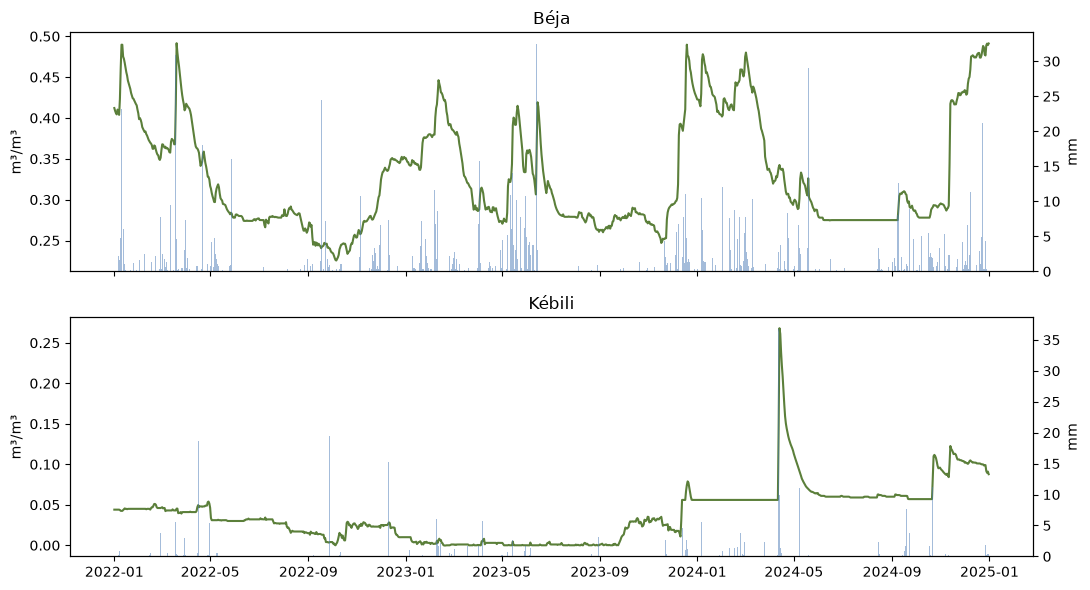

In [4]:
# Aperçu : un site du Nord et une oasis du Sud
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for a, sid in zip(ax, ["beja", "kebili"]):
    d = data[(data.site == sid) & (data.date.dt.year >= 2022)]
    a.plot(d.date, d.sm_7_28, color="#5b7f3a", label="Humidité du sol 7–28 cm")
    a2 = a.twinx(); a2.bar(d.date, d.pluie, color="#4a7bb7", alpha=.5, width=1, label="Pluie (mm)")
    a.set_title(SITES.set_index("id").nom[sid]); a.set_ylabel("m³/m³"); a2.set_ylabel("mm")
fig.tight_layout()

## 3. Construction des variables
Pour chaque jour *J* et chaque site :
- **état actuel du sol** : humidité aux 3 profondeurs, valeurs des jours précédents, variation de la veille ;
- **historique météo** : pluie cumulée sur 1, 3, 7, 30 jours ; ET0 cumulée sur 3, 7, 30 jours ;
- **météo des h prochains jours** (en usage réel : la prévision Open-Meteo) ;
- **lieu et saison** : latitude, longitude, altitude, jour de l'année (sinus / cosinus).

**Cible** pour l'horizon *h* : `humidité(J+h) − humidité(J)`.

In [5]:
def construire_variables(df):
    g = df.sort_values("date").copy()
    s = g[CIBLE]
    for l in [1, 2, 3, 7]:
        g[f"sm_lag{l}"] = s.shift(l)
    g["sm_diff1"] = s - s.shift(1)
    for w in [1, 3, 7, 30]:
        g[f"pluie_{w}j"] = g.pluie.rolling(w).sum()
    for w in [3, 7, 30]:
        g[f"et0_{w}j"] = g.et0.rolling(w).sum()
    doy = g.date.dt.day_of_year
    g["saison_sin"], g["saison_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    for h in HORIZONS:
        futur_pluie = pd.concat([g.pluie.shift(-k) for k in range(1, h + 1)], axis=1)
        futur_et0   = pd.concat([g.et0.shift(-k)   for k in range(1, h + 1)], axis=1)
        g[f"pluie_fut_{h}"]     = futur_pluie.sum(axis=1, min_count=h)
        g[f"pluie_max_fut_{h}"] = futur_pluie.max(axis=1)
        g[f"et0_fut_{h}"]       = futur_et0.sum(axis=1, min_count=h)
        g[f"cible_{h}"]         = s.shift(-h) - s
    return g


BASE = ["sm_0_7", "sm_7_28", "sm_28_100", "sm_lag1", "sm_lag2", "sm_lag3", "sm_lag7", "sm_diff1",
        "pluie", "et0", "tmax", "tmin", "rayonnement", "vent",
        "pluie_1j", "pluie_3j", "pluie_7j", "pluie_30j", "et0_3j", "et0_7j", "et0_30j",
        "lat", "lon", "altitude", "saison_sin", "saison_cos"]
variables = lambda h: BASE + [f"pluie_fut_{h}", f"pluie_max_fut_{h}", f"et0_fut_{h}"]

table = pd.concat([construire_variables(g) for _, g in data.groupby("site")], ignore_index=True)
annee = table.date.dt.year
ENTRAIN   = (~table.test_geo) & (annee <= 2020)
VALID     = (~table.test_geo) & (annee == 2021)
TEST_TEMP = (~table.test_geo) & (annee >= 2022)     # années jamais vues
TEST_GEO  = ( table.test_geo) & (annee >= 2022)     # lieux ET années jamais vus
print({k: int(v.sum()) for k, v in dict(entrainement=ENTRAIN, validation=VALID,
                                        test_annees=TEST_TEMP, test_lieux=TEST_GEO).items()})

{'entrainement': 40194, 'validation': 8030, 'test_annees': 24112, 'test_lieux': 4384}


## 4. Entraînement : un modèle LightGBM par horizon

In [6]:
def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

modeles, resultats = {}, []
for h in HORIZONS:
    X, y = variables(h), f"cible_{h}"
    ok = table[X + [y]].notna().all(axis=1)
    tr, va = table[ENTRAIN & ok], table[VALID & ok]
    m = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.03, num_leaves=63, min_child_samples=40,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
    m.fit(tr[X], tr[y], eval_set=[(va[X], va[y])], callbacks=[lgb.early_stopping(100, verbose=False)])
    modeles[h] = m
    for nom, masque in [("années jamais vues", TEST_TEMP), ("lieux jamais vus", TEST_GEO)]:
        te = table[masque & ok]
        vrai = te[CIBLE] + te[y]                 # humidité réelle à J+h
        pred = te[CIBLE] + m.predict(te[X])      # humidité prédite à J+h
        r_mod, r_per = rmse(vrai, pred), rmse(vrai, te[CIBLE])
        resultats.append(dict(horizon=h, test=nom, rmse_modele=r_mod, rmse_persistance=r_per,
                              gain=1 - r_mod / r_per, arbres=m.best_iteration_))
    print(f"J+{h} entraîné ({m.best_iteration_} arbres)")

res = pd.DataFrame(resultats)
res.pivot(index="horizon", columns="test", values=["rmse_modele", "rmse_persistance", "gain"]).round(4)

J+1 entraîné (307 arbres)


J+2 entraîné (191 arbres)


J+3 entraîné (340 arbres)


J+4 entraîné (418 arbres)


J+5 entraîné (426 arbres)


J+6 entraîné (458 arbres)


J+7 entraîné (373 arbres)


rmse_modele                    rmse_persistance  \
test    années jamais vues lieux jamais vus années jamais vues   
horizon                                                          
1                   0.0043           0.0043             0.0068   
2                   0.0073           0.0078             0.0116   
3                   0.0094           0.0099             0.0152   
4                   0.0110           0.0115             0.0182   
5                   0.0123           0.0125             0.0207   
6                   0.0135           0.0136             0.0230   
7                   0.0145           0.0144             0.0250   

                                       gain                   
test    lieux jamais vus années jamais vues lieux jamais vus  
horizon                                                       
1                 0.0068             0.3580           0.3652  
2                 0.0118             0.3678           0.3367  
3                 0.0155             0.3848           0.3615  
4                 0.0186             0.3950           0.3804  
5                 0.0211             0.4076           0.4054  
6                 0.0233             0.4132           0.4152  
7                 0.0253             0.4202           0.4305

## 5. Résultats
**RMSE** = erreur moyenne en m³/m³ (plus c'est bas, mieux c'est). **Gain** = réduction de l'erreur par rapport à la persistance.

Réduction moyenne de l'erreur par rapport à la persistance :
  années jamais vues   39%
  lieux jamais vus     38%


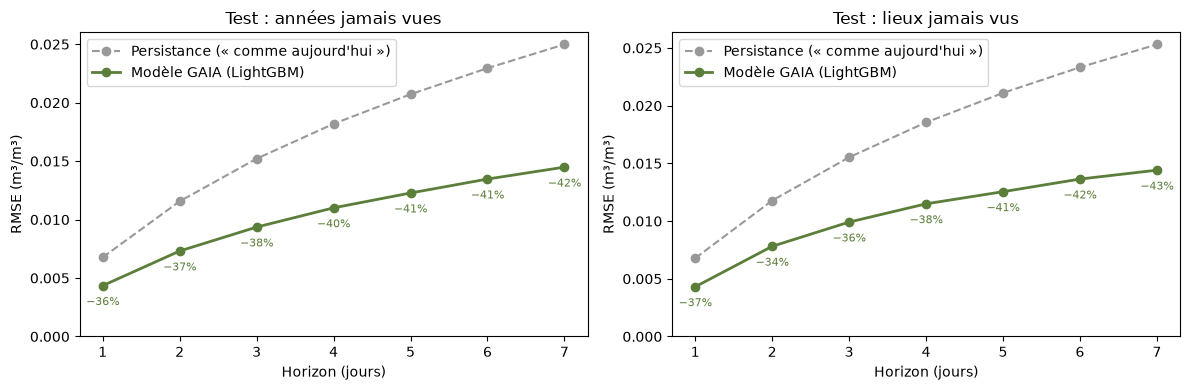

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, nom in zip(ax, ["années jamais vues", "lieux jamais vus"]):
    r = res[res.test == nom]
    a.plot(r.horizon, r.rmse_persistance, "o--", color="#999", label="Persistance (« comme aujourd'hui »)")
    a.plot(r.horizon, r.rmse_modele, "o-", color="#5b7f3a", lw=2, label="Modèle GAIA (LightGBM)")
    for _, row in r.iterrows():
        a.annotate(f"−{row.gain:.0%}", (row.horizon, row.rmse_modele), textcoords="offset points",
                   xytext=(0, -14), ha="center", fontsize=8, color="#5b7f3a")
    a.set_title(f"Test : {nom}"); a.set_xlabel("Horizon (jours)"); a.set_ylabel("RMSE (m³/m³)"); a.legend()
    a.set_ylim(bottom=0)
fig.tight_layout()

g = res.groupby("test").gain.mean()
print("Réduction moyenne de l'erreur par rapport à la persistance :")
for k, v in g.items():
    print(f"  {k:20s} {v:.0%}")

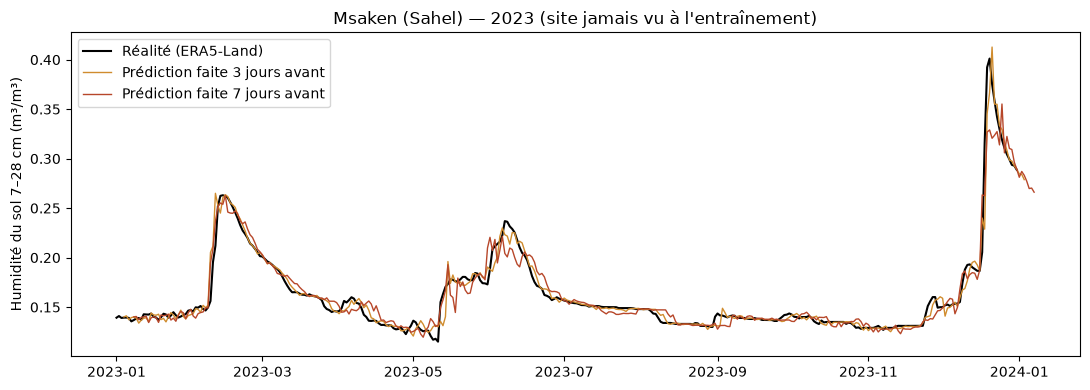

In [8]:
# Exemple sur un site jamais vu : prédiction à J+3 et J+7 comparée à la réalité
SITE_EX = "msaken"
d = table[(table.site == SITE_EX) & (table.date.dt.year == 2023)].copy()
fig, ax = plt.subplots()
ax.plot(d.date, d[CIBLE], color="black", lw=1.5, label="Réalité (ERA5-Land)")
for h, c in [(3, "#d08c2e"), (7, "#b7472a")]:
    X = variables(h); ok = d[X].notna().all(axis=1)
    pred = d.loc[ok, CIBLE] + modeles[h].predict(d.loc[ok, X])
    ax.plot(d.loc[ok, "date"] + pd.Timedelta(days=h), pred, color=c, lw=1, label=f"Prédiction faite {h} jours avant")
ax.set_title(f"{SITES.set_index('id').nom[SITE_EX]} — 2023 (site jamais vu à l'entraînement)")
ax.set_ylabel("Humidité du sol 7–28 cm (m³/m³)"); ax.legend()
fig.tight_layout()

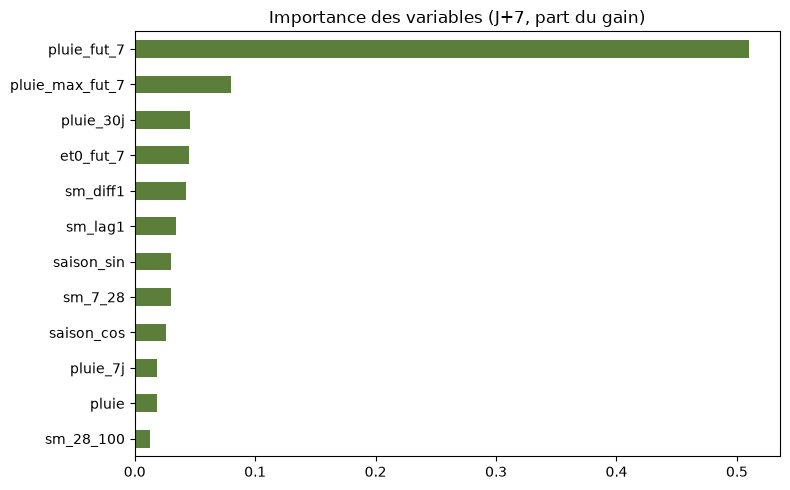

In [9]:
# Ce qui compte le plus pour prédire à J+7
h = 7
imp = pd.Series(modeles[h].booster_.feature_importance("gain"), index=variables(h))
imp = (imp / imp.sum()).sort_values()[-12:]
imp.plot.barh(color="#5b7f3a", figsize=(8, 5), title="Importance des variables (J+7, part du gain)")
plt.tight_layout()

## 6. Sauvegarde des modèles
Les fichiers de `models/` peuvent être chargés par le backend FastAPI (`lightgbm.Booster(model_file=...)`).

In [10]:
for h, m in modeles.items():
    m.booster_.save_model(str(MODEL_DIR / f"humidite_sol_J{h}.txt"))
# seuils sec / humide de chaque site : 5e et 95e centiles de son humidité historique
seuils = data.groupby("site")[CIBLE].quantile([0.05, 0.95]).unstack()
meta = dict(cible=CIBLE, horizons=list(HORIZONS), variables={h: variables(h) for h in HORIZONS},
            source="Open-Meteo Historical API (ERA5 / ERA5-Land)", periode=[START, END],
            resultats=res.round(5).to_dict("records"),
            seuils_sites={s: dict(sec=round(r[0.05], 4), humide=round(r[0.95], 4)) for s, r in seuils.iterrows()},
            sites=SITES[SITES.id.isin(data.site.unique())][["id", "nom", "lat", "lon", "zone"]].to_dict("records"))
# prédiction de référence : permet au backend de vérifier qu'il calcule exactement comme ce notebook
ref = table[(table.site == "msaken") & (table.date == "2023-06-18")]
meta["exemple"] = dict(site="msaken", date="2023-06-18",
                       predictions={h: float(ref[CIBLE].iloc[0] + modeles[h].predict(ref[variables(h)])[0]) for h in HORIZONS})
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")
sorted(p.name for p in MODEL_DIR.iterdir())

['bascule_7j.txt',
 'bascule_meta.json',
 'humidite_sol_J1.txt',
 'humidite_sol_J2.txt',
 'humidite_sol_J3.txt',
 'humidite_sol_J4.txt',
 'humidite_sol_J5.txt',
 'humidite_sol_J6.txt',
 'humidite_sol_J7.txt',
 'meta.json']

## 7. De la prédiction à la décision d'irrigation
Pour rester honnête sans inventer de propriétés de sol, la **réserve** est exprimée par rapport à l'historique du site :
0 % = aussi sec que les 5 % des jours les plus secs, 100 % = aussi humide que les 5 % les plus humides.

**Hypothèse de démonstration** (à remplacer par les seuils de la culture, FAO-56) : *irriguer* quand la réserve prévue passe sous **30 %**, *bientôt* sous **35 %**.

In [11]:
SEUIL_IRRIGATION = 0.30
SEUIL_ALERTE = 0.35        # « bientôt » : la réserve approche du seuil

def reserve(theta, site_id):
    lo, hi = seuils.loc[site_id, 0.05], seuils.loc[site_id, 0.95]
    return float(np.clip((theta - lo) / (hi - lo), 0, 1))


def plan_7_jours(t, site_id):
    # t : table de variables du site ; la dernière ligne = aujourd'hui
    jour = t.iloc[-1]
    lignes = []
    for h in HORIZONS:
        theta = jour[CIBLE] + modeles[h].predict(t.iloc[[-1]][variables(h)])[0]
        r = reserve(theta, site_id)
        d = jour.date + pd.Timedelta(days=h)
        lignes.append(dict(jour=f"{JOURS[d.weekday()]} {d:%d/%m}",
                           pluie_prevue_mm=round(jour[f"pluie_fut_{h}"] - (jour[f"pluie_fut_{h-1}"] if h > 1 else 0), 1),
                           humidite_prevue=round(theta, 3), reserve=f"{r:.0%}",
                           decision="💧 irriguer" if r < SEUIL_IRRIGATION else ("⚠️ bientôt" if r < SEUIL_ALERTE else "—")))
    return pd.DataFrame(lignes)


# Démonstration sur un site jamais vu, en juin 2023, comparée à ce qui s'est réellement passé
site_id, date = "msaken", pd.Timestamp("2023-06-18")
t = table[(table.site == site_id) & (table.date <= date)]
plan = plan_7_jours(t, site_id)
reel = table[(table.site == site_id) & (table.date > date)].head(7)[CIBLE].round(3).values
plan["humidite_reelle"] = reel
plan["reserve_reelle"] = [f"{reserve(v, site_id):.0%}" for v in reel]
print(f"Plan pour {SITES.set_index('id').nom[site_id]} à partir du {date:%d/%m/%Y} "
      f"(réserve aujourd'hui : {reserve(t.iloc[-1][CIBLE], site_id):.0%})")
plan

Plan pour Msaken (Sahel) à partir du 18/06/2023 (réserve aujourd'hui : 39%)


,jour,pluie_prevue_mm,humidite_prevue,reserve,decision,humidite_reelle,reserve_reelle
0,lun 19/06,0.0,0.177,36%,—,0.175,35%
1,mar 20/06,0.0,0.173,34%,⚠️ bientôt,0.171,33%
2,mer 21/06,0.0,0.171,33%,⚠️ bientôt,0.170,32%
3,jeu 22/06,0.0,0.169,31%,⚠️ bientôt,0.168,31%
4,ven 23/06,0.0,0.168,31%,⚠️ bientôt,0.162,27%
5,sam 24/06,0.0,0.168,31%,⚠️ bientôt,0.161,27%
6,dim 25/06,0.0,0.167,30%,⚠️ bientôt,0.160,26%


## 8. Prévision réelle pour la semaine qui vient (nécessite internet)
On prend l'état du sol le plus récent fourni par Open-Meteo (ERA5-Land est publié avec ~5 jours de retard ; les derniers jours peuvent venir d'un modèle de prévision), puis la **prévision météo Open-Meteo** pour les jours suivants. Changez `LAT`, `LON` pour votre parcelle.

In [12]:
LAT, LON = 35.73, 10.58      # Msaken, Sahel — mettez ici les coordonnées de la parcelle

try:
    fin = pd.Timestamp.today().normalize()
    j = appel_open_meteo(URL, dict(latitude=LAT, longitude=LON, start_date=(fin - pd.Timedelta(days=75)).date(),
                                   end_date=fin.date(), daily=",".join(DAILY), hourly=",".join(HOURLY),
                                   timezone="Africa/Tunis"))
    hist = json_vers_table(j)
    hist["altitude"], hist["lat"], hist["lon"] = j["elevation"], LAT, LON
    hist = hist[hist.date <= hist.dropna(subset=[CIBLE, "et0", "pluie"]).date.max()]   # dernier jour complet
    prev = appel_open_meteo("https://api.open-meteo.com/v1/forecast",
                            dict(latitude=LAT, longitude=LON, past_days=14, forecast_days=16, timezone="Africa/Tunis",
                                 daily="et0_fao_evapotranspiration,precipitation_sum"))
    prev = pd.DataFrame(prev["daily"]).rename(columns=RENOMMER)
    prev["date"] = pd.to_datetime(prev.pop("time"))
    futur = prev[prev.date > hist.date.max()].head(7)
    t = construire_variables(pd.concat([hist, futur], ignore_index=True))
    t = t[t.date <= hist.date.max()]
    site_proche = SITES.assign(d=(SITES.lat - LAT) ** 2 + (SITES.lon - LON) ** 2).sort_values("d").id.iloc[0]
    print(f"État du sol le plus récent fourni par Open-Meteo : {hist.date.max():%d/%m/%Y} "
          "(les tout derniers jours peuvent venir d'un modèle de prévision plutôt que d'ERA5-Land).")
    print("Météo des jours suivants = prévision Open-Meteo.")
    print(f"Seuils sec/humide empruntés au site d'entraînement le plus proche : {site_proche}")
    display(plan_7_jours(t, site_proche))
except Exception as e:
    print("Prévision en direct indisponible :", e)

État du sol le plus récent fourni par Open-Meteo : 21/11/2026 (les tout derniers jours peuvent venir d'un modèle de prévision plutôt que d'ERA5-Land).
Météo des jours suivants = prévision Open-Meteo.
Seuils sec/humide empruntés au site d'entraînement le plus proche : msaken


,jour,pluie_prevue_mm,humidite_prevue,reserve,decision
0,dim 22/11,0.0,0.217,60%,—
1,lun 23/11,0.0,0.215,58%,—
2,mar 24/11,0.0,0.213,57%,—
3,mer 25/11,0.0,0.212,57%,—
4,jeu 26/11,0.6,0.211,56%,—
5,ven 27/11,3.0,0.212,57%,—
6,sam 28/11,0.0,0.212,56%,—


## 9. Évaluation complète : R², erreur en mm, décision « irriguer »
Chaque métrique est comparée à la **persistance** (« comme aujourd'hui »), sinon elle ne veut rien dire :
- **R² de l'humidité** : gonflé, car le sol change lentement ; la persistance a déjà un R² très élevé.
- **R² de la variation** : *le chiffre honnête*. Part des **changements** d'humidité que le modèle prévoit.
- **MAE / RMSE en mm d'eau** dans la couche 7–28 cm (210 mm d'épaisseur) ; **biais** = erreur systématique.
- **Décision « irriguer »** (réserve < 30 %) : exactitude, précision, rappel, F1.

1) QUALITÉ DE LA PRÉDICTION D'HUMIDITÉ


test,horizon,R² humidité,R² persistance,R² variation,MAE (mm),RMSE (mm),Biais (mm),Gain vs persistance
années jamais vues,J+1,0.998,0.995,0.588,0.42,0.91,-0.02,36%
années jamais vues,J+2,0.994,0.985,0.600,0.73,1.53,-0.05,37%
années jamais vues,J+3,0.990,0.974,0.621,0.99,1.97,-0.07,38%
années jamais vues,J+4,0.986,0.962,0.634,1.22,2.31,-0.09,40%
années jamais vues,J+5,0.983,0.951,0.649,1.41,2.58,-0.13,41%
années jamais vues,J+6,0.979,0.940,0.656,1.58,2.83,-0.16,41%
années jamais vues,J+7,0.976,0.929,0.664,1.74,3.04,-0.19,42%
lieux jamais vus,J+1,0.997,0.993,0.597,0.42,0.90,-0.02,37%
lieux jamais vus,J+2,0.991,0.979,0.560,0.74,1.64,-0.06,34%
lieux jamais vus,J+3,0.985,0.963,0.592,0.99,2.08,-0.08,36%



2) QUALITÉ DE LA DÉCISION « IRRIGUER » (réserve < 30 %)


test,horizon,jours « irriguer » réels,Exactitude,Précision,Rappel,F1,F1 persistance
années jamais vues,J+1,10187,98.8%,98.6%,98.7%,98.6%,98.3%
années jamais vues,J+2,10180,98.0%,97.5%,97.8%,97.7%,97.1%
années jamais vues,J+3,10173,97.4%,96.7%,97.2%,97.0%,96.1%
années jamais vues,J+4,10166,97.0%,96.2%,96.7%,96.5%,95.1%
années jamais vues,J+5,10159,96.6%,95.8%,96.3%,96.0%,94.2%
années jamais vues,J+6,10152,96.2%,95.2%,95.7%,95.5%,93.3%
années jamais vues,J+7,10144,95.6%,94.4%,95.3%,94.9%,92.4%
lieux jamais vus,J+1,1474,98.5%,97.9%,97.8%,97.8%,97.8%
lieux jamais vus,J+2,1472,97.6%,96.8%,96.1%,96.4%,96.6%
lieux jamais vus,J+3,1470,97.2%,96.2%,95.5%,95.8%,95.6%


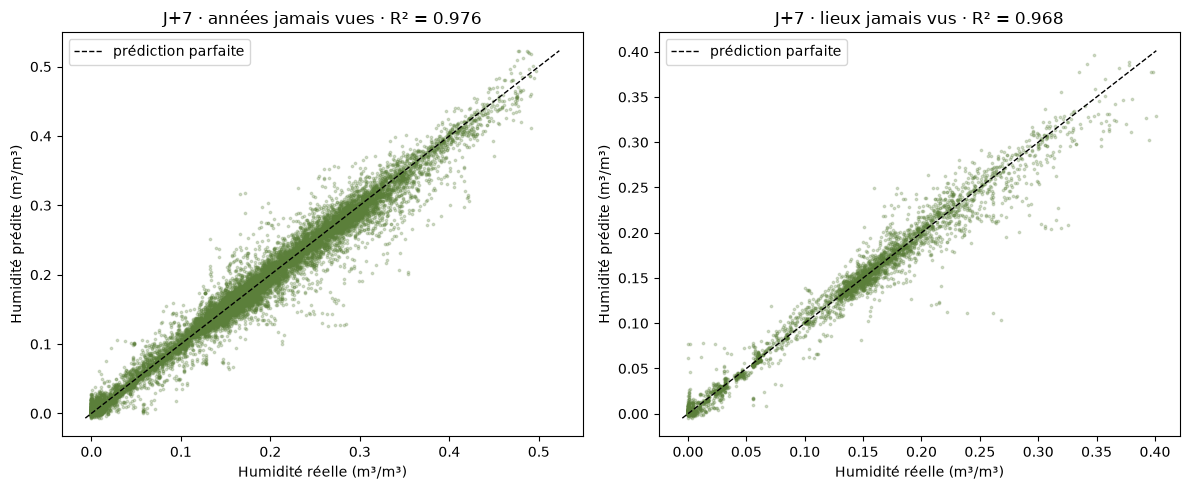


▶ ANNÉES JAMAIS VUES
  R² de l'humidité : 0.976 à 0.998 (persistance : 0.929 à 0.995)
  R² de la variation (ce qui va changer) : 0.59 à J+1, 0.66 à J+7
  Erreur moyenne : 0.4 mm d'eau à J+1, 1.7 mm à J+7
  Décision « irriguer » à J+7 : précision 94%, rappel 95%, F1 95% (persistance : F1 92%)

▶ LIEUX JAMAIS VUS
  R² de l'humidité : 0.968 à 0.997 (persistance : 0.901 à 0.993)
  R² de la variation (ce qui va changer) : 0.60 à J+1, 0.68 à J+7
  Erreur moyenne : 0.4 mm d'eau à J+1, 1.7 mm à J+7
  Décision « irriguer » à J+7 : précision 93%, rappel 93%, F1 93% (persistance : F1 92%)


In [13]:
# ==========================================================
# ÉVALUATION COMPLÈTE DU MODÈLE
# ==========================================================
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             precision_score, recall_score, f1_score, accuracy_score)

MM = 210   # couche 7–28 cm = 210 mm : 0,01 m³/m³ d'erreur = 2,1 mm d'eau

lignes, decisions, nuages = [], [], {}
for nom, masque in [("années jamais vues", TEST_TEMP), ("lieux jamais vus", TEST_GEO)]:
    for h in HORIZONS:
        X, y = variables(h), f"cible_{h}"
        te = table[masque & table[X + [y]].notna().all(axis=1)]
        auj = te[CIBLE].values
        vrai_var, pred_var = te[y].values, modeles[h].predict(te[X])
        vrai, pred = auj + vrai_var, auj + pred_var
        rmse_m = np.sqrt(mean_squared_error(vrai, pred))
        rmse_p = np.sqrt(mean_squared_error(vrai, auj))
        lignes.append({"test": nom, "horizon": f"J+{h}",
                       "R² humidité": r2_score(vrai, pred),
                       "R² persistance": r2_score(vrai, auj),
                       "R² variation": r2_score(vrai_var, pred_var),
                       "MAE (mm)": mean_absolute_error(vrai, pred) * MM,
                       "RMSE (mm)": rmse_m * MM,
                       "Biais (mm)": (pred - vrai).mean() * MM,
                       "Gain vs persistance": 1 - rmse_m / rmse_p})
        # la décision « irriguer » (réserve < 30 %) : le modèle l'annonce-t-il au bon moment ?
        lo = te.site.map(seuils[0.05]).values
        hi = te.site.map(seuils[0.95]).values
        sec_vrai = (vrai - lo) / (hi - lo) < SEUIL_IRRIGATION
        sec_pred = (pred - lo) / (hi - lo) < SEUIL_IRRIGATION
        sec_auj = (auj - lo) / (hi - lo) < SEUIL_IRRIGATION     # persistance : « comme aujourd'hui »
        decisions.append({"test": nom, "horizon": f"J+{h}",
                          "jours « irriguer » réels": int(sec_vrai.sum()),
                          "Exactitude": accuracy_score(sec_vrai, sec_pred),
                          "Précision": precision_score(sec_vrai, sec_pred, zero_division=0),
                          "Rappel": recall_score(sec_vrai, sec_pred, zero_division=0),
                          "F1": f1_score(sec_vrai, sec_pred, zero_division=0),
                          "F1 persistance": f1_score(sec_vrai, sec_auj, zero_division=0)})
        if h == 7:
            nuages[nom] = (vrai, pred)

metriques = pd.DataFrame(lignes)
print("1) QUALITÉ DE LA PRÉDICTION D'HUMIDITÉ")
display(metriques.style.format({"R² humidité": "{:.3f}", "R² persistance": "{:.3f}", "R² variation": "{:.3f}", "MAE (mm)": "{:.2f}",
                                "RMSE (mm)": "{:.2f}", "Biais (mm)": "{:+.2f}", "Gain vs persistance": "{:.0%}"})
        .hide(axis="index"))

print("\n2) QUALITÉ DE LA DÉCISION « IRRIGUER » (réserve < 30 %)")
display(pd.DataFrame(decisions).style.format({"Exactitude": "{:.1%}", "Précision": "{:.1%}",
                                              "Rappel": "{:.1%}", "F1": "{:.1%}", "F1 persistance": "{:.1%}"}).hide(axis="index"))

# 3) nuage de points : prédit vs réel à J+7
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, (nom, (vrai, pred)) in zip(ax, nuages.items()):
    a.scatter(vrai, pred, s=3, alpha=.25, color="#5b7f3a")
    lim = [min(vrai.min(), pred.min()), max(vrai.max(), pred.max())]
    a.plot(lim, lim, "k--", lw=1, label="prédiction parfaite")
    a.set_title(f"J+7 · {nom} · R² = {r2_score(vrai, pred):.3f}")
    a.set_xlabel("Humidité réelle (m³/m³)"); a.set_ylabel("Humidité prédite (m³/m³)"); a.legend()
fig.tight_layout(); plt.show()

# 4) résumé en clair
for nom in ["années jamais vues", "lieux jamais vus"]:
    m = metriques[metriques.test == nom].set_index("horizon")
    d = pd.DataFrame(decisions)
    d = d[d.test == nom].set_index("horizon")
    print(f"\n▶ {nom.upper()}")
    print(f"  R² de l'humidité : {m['R² humidité'].min():.3f} à {m['R² humidité'].max():.3f} "
          f"(persistance : {m['R² persistance'].min():.3f} à {m['R² persistance'].max():.3f})")
    print(f"  R² de la variation (ce qui va changer) : {m.loc['J+1', 'R² variation']:.2f} à J+1, {m.loc['J+7', 'R² variation']:.2f} à J+7")
    print(f"  Erreur moyenne : {m.loc['J+1', 'MAE (mm)']:.1f} mm d'eau à J+1, {m.loc['J+7', 'MAE (mm)']:.1f} mm à J+7")
    print(f"  Décision « irriguer » à J+7 : précision {d.loc['J+7', 'Précision']:.0%}, rappel {d.loc['J+7', 'Rappel']:.0%}, "
          f"F1 {d.loc['J+7', 'F1']:.0%} (persistance : F1 {d.loc['J+7', 'F1 persistance']:.0%})")

## 10. Piste d'amélioration : les moments de bascule
La section 9 montre que la décision « irriguer » n'est qu'un peu meilleure que la persistance : un sol sec reste souvent sec des semaines, donc « comme aujourd'hui » a presque toujours raison. **La décision ne compte vraiment qu'au moment où la réserve passe sous le seuil** : c'est là qu'il faut prévenir l'agriculteur.

On isole donc ces moments. Parmi les jours où la réserve est **encore au-dessus de 30 %**, on se pose une seule question :
> **La réserve va-t-elle passer sous 30 % dans les 7 prochains jours, et quel jour ?**

Quatre méthodes, comparées sur les mêmes jours :
1. **Persistance** : « comme aujourd'hui », donc ne prévoit jamais de bascule.
2. **Tendance** : prolonge la pente des 3 derniers jours.
3. **Trajectoire du modèle** : les 7 modèles de régression ; bascule si une des 7 prévisions passe sous 30 %.
4. **Modèle dédié aux bascules** : un classifieur LightGBM entraîné uniquement sur ces jours, avec la réserve relative et sa pente comme variables, et un seuil de probabilité réglé sur 2021.

Pour éviter toute fuite d'information, les seuils sec/humide de chaque site sont ici calculés **sur les années d'entraînement seulement** (2016–2020).

In [14]:
# 10a. Les moments de bascule
seuils_ent = table[annee <= 2020].groupby("site")[CIBLE].quantile([0.05, 0.95]).unstack()
LO, HI = table.site.map(seuils_ent[0.05]), table.site.map(seuils_ent[0.95])

def rel(theta):
    # humidité → réserve relative au site (0 = sec, 1 = humide), même index que theta
    lo, hi = LO.loc[theta.index], HI.loc[theta.index]
    return (theta - lo) / (hi - lo)

table["reserve_auj"] = rel(table[CIBLE])
table["reserve_lag1"] = rel(table.sm_lag1)
table["reserve_lag3"] = rel(table.sm_lag3)
table["reserve_pente3"] = (table.reserve_auj - table.reserve_lag3) / 3

reserve_vraie = pd.concat({h: rel(table[CIBLE] + table[f"cible_{h}"]) for h in HORIZONS}, axis=1)
sous_vrai = reserve_vraie < SEUIL_IRRIGATION
complet = reserve_vraie.notna().all(axis=1) & table[variables(7) + ["reserve_lag3"]].notna().all(axis=1)
POP = complet & (table.reserve_auj >= SEUIL_IRRIGATION)          # jours encore au-dessus du seuil
table["bascule_7j"] = sous_vrai.any(axis=1)
table["jour_bascule"] = sous_vrai.idxmax(axis=1).where(sous_vrai.any(axis=1))

for nom, m in [("entraînement", ENTRAIN), ("validation 2021", VALID), ("test années", TEST_TEMP), ("test lieux", TEST_GEO)]:
    d = table[m & POP]
    print(f"{nom:16s} {len(d):6d} jours au-dessus du seuil, dont {int(d.bascule_7j.sum()):5d} bascules dans les 7 jours "
          f"({d.bascule_7j.mean():.1%})")

entraînement      27292 jours au-dessus du seuil, dont  1481 bascules dans les 7 jours (5.4%)
validation 2021    3783 jours au-dessus du seuil, dont   184 bascules dans les 7 jours (4.9%)
test années       12922 jours au-dessus du seuil, dont   888 bascules dans les 7 jours (6.9%)
test lieux         2716 jours au-dessus du seuil, dont   129 bascules dans les 7 jours (4.7%)


In [15]:
# 10b. Les méthodes simples : persistance, tendance, trajectoire des 7 modèles
def premier_jour(sous):
    # premier horizon où la réserve est sous le seuil, NaN s'il n'y en a pas
    return sous.idxmax(axis=1).where(sous.any(axis=1))

def trajectoire_modele(d):
    return pd.concat({h: rel(pd.Series(d[CIBLE].values + modeles[h].predict(d[variables(h)]), index=d.index))
                      for h in HORIZONS}, axis=1)

def trajectoire_tendance(d):
    return pd.concat({h: d.reserve_auj + h * d.reserve_pente3 for h in HORIZONS}, axis=1)

In [16]:
# 10c. Le modèle dédié aux bascules (classifieur LightGBM)
VAR_BASCULE = BASE + ["reserve_auj", "reserve_lag1", "reserve_lag3", "reserve_pente3",
                      "pluie_fut_3", "et0_fut_3", "pluie_fut_7", "pluie_max_fut_7", "et0_fut_7"]
tr, va = table[ENTRAIN & POP], table[VALID & POP]
# les bascules sont rares (~5 %) : on suit la précision moyenne (average precision) plutôt que l'exactitude,
# et c'est le seuil de probabilité réglé plus bas qui gère le déséquilibre
clf = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.02, num_leaves=15, min_child_samples=60,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, verbose=-1)
clf.fit(tr[VAR_BASCULE], tr.bascule_7j, eval_set=[(va[VAR_BASCULE], va.bascule_7j)], eval_metric="average_precision",
        callbacks=[lgb.early_stopping(200, verbose=False, first_metric_only=False)])

# seuil de probabilité réglé sur 2021 (jamais sur les années de test)
proba_va = clf.predict_proba(va[VAR_BASCULE])[:, 1]
grille = np.linspace(0.05, 0.95, 91)
SEUIL_PROBA = float(grille[np.argmax([f1_score(va.bascule_7j, proba_va >= s) for s in grille])])
print(f"Classifieur : {clf.best_iteration_} arbres, seuil de probabilité retenu = {SEUIL_PROBA:.2f}")

Classifieur : 107 arbres, seuil de probabilité retenu = 0.40


1) LE MODÈLE ANNONCE-T-IL LA BASCULE ? (sur les jours encore au-dessus de 30 %)


test,méthode,bascules réelles,bascules annoncées,Précision,Rappel,F1
années jamais vues,Persistance,888,0,0.0%,0.0%,0.0%
années jamais vues,Tendance (3 derniers jours),888,1158,39.2%,51.1%,44.4%
années jamais vues,Trajectoire des 7 modèles,888,805,61.5%,55.7%,58.5%
années jamais vues,Modèle dédié aux bascules,888,848,61.7%,58.9%,60.3%
lieux jamais vus,Persistance,129,0,0.0%,0.0%,0.0%
lieux jamais vus,Tendance (3 derniers jours),129,195,29.2%,44.2%,35.2%
lieux jamais vus,Trajectoire des 7 modèles,129,79,73.4%,45.0%,55.8%
lieux jamais vus,Modèle dédié aux bascules,129,152,51.3%,60.5%,55.5%



2) ANNONCE-T-IL LE BON JOUR ? (bascules réelles bien détectées ; retard > 0 = annoncée trop tard)


test,méthode,bascules détectées,bon jour,à ±1 jour,écart moyen (jours),retard moyen (jours)
années jamais vues,Trajectoire des 7 modèles,495,28%,60%,1.51,+0.49
années jamais vues,Modèle dédié aux bascules,523,29%,58%,1.63,+0.67
lieux jamais vus,Trajectoire des 7 modèles,58,31%,64%,1.45,+0.93
lieux jamais vus,Modèle dédié aux bascules,78,28%,56%,1.85,+1.21


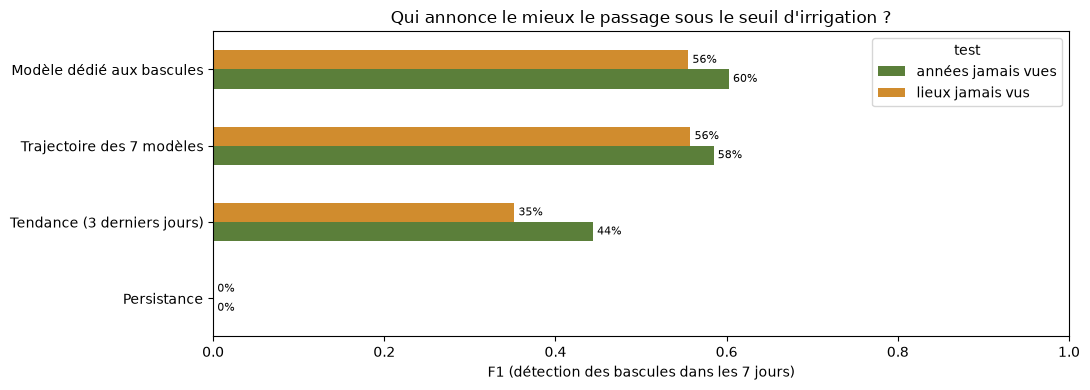

In [17]:
# 10d. Comparaison sur les années et les lieux jamais vus
resultats_bascule, timing = [], []
for nom, masque in [("années jamais vues", TEST_TEMP), ("lieux jamais vus", TEST_GEO)]:
    d = table[masque & POP]
    vrai, jour_vrai = d.bascule_7j.values, d.jour_bascule
    traj = trajectoire_modele(d)
    jour_traj = premier_jour(traj < SEUIL_IRRIGATION)
    # jour annoncé par le classifieur : premier jour sous le seuil sur la trajectoire, sinon le jour le plus sec
    jour_clf = jour_traj.fillna(traj.idxmin(axis=1))
    proba = clf.predict_proba(d[VAR_BASCULE])[:, 1]
    methodes = {
        "Persistance": (np.zeros(len(d), bool), None),
        "Tendance (3 derniers jours)": ((trajectoire_tendance(d) < SEUIL_IRRIGATION).any(axis=1).values, None),
        "Trajectoire des 7 modèles": (jour_traj.notna().values, jour_traj),
        "Modèle dédié aux bascules": (proba >= SEUIL_PROBA, jour_clf),
    }
    for meth, (pred, jour) in methodes.items():
        resultats_bascule.append({"test": nom, "méthode": meth, "bascules réelles": int(vrai.sum()),
                                  "bascules annoncées": int(pred.sum()),
                                  "Précision": precision_score(vrai, pred, zero_division=0),
                                  "Rappel": recall_score(vrai, pred, zero_division=0),
                                  "F1": f1_score(vrai, pred, zero_division=0)})
        if jour is not None:
            ok = vrai & pred                                    # bascules réelles bien détectées
            ecart = (jour[ok] - jour_vrai[ok]).values
            timing.append({"test": nom, "méthode": meth, "bascules détectées": int(ok.sum()),
                           "bon jour": np.mean(ecart == 0), "à ±1 jour": np.mean(np.abs(ecart) <= 1),
                           "écart moyen (jours)": np.mean(np.abs(ecart)), "retard moyen (jours)": np.mean(ecart)})

rb = pd.DataFrame(resultats_bascule)
print("1) LE MODÈLE ANNONCE-T-IL LA BASCULE ? (sur les jours encore au-dessus de 30 %)")
display(rb.style.format({"Précision": "{:.1%}", "Rappel": "{:.1%}", "F1": "{:.1%}"}).hide(axis="index"))
print("\n2) ANNONCE-T-IL LE BON JOUR ? (bascules réelles bien détectées ; retard > 0 = annoncée trop tard)")
display(pd.DataFrame(timing).style.format({"bon jour": "{:.0%}", "à ±1 jour": "{:.0%}", "écart moyen (jours)": "{:.2f}",
                                           "retard moyen (jours)": "{:+.2f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 4))
piv = rb.pivot(index="méthode", columns="test", values="F1").loc[[m for m in methodes]]
piv.plot.barh(ax=ax, color=["#5b7f3a", "#d08c2e"])
ax.set_xlabel("F1 (détection des bascules dans les 7 jours)"); ax.set_xlim(0, 1); ax.set_ylabel("")
ax.set_title("Qui annonce le mieux le passage sous le seuil d'irrigation ?")
for c in ax.containers:
    ax.bar_label(c, fmt="{:.0%}", padding=3, fontsize=8)
fig.tight_layout(); plt.show()

In [18]:
# 10e. Sauvegarde du modèle dédié aux bascules
clf.booster_.save_model(str(MODEL_DIR / "bascule_7j.txt"))
(MODEL_DIR / "bascule_meta.json").write_text(json.dumps(dict(
    question="la réserve passe-t-elle sous le seuil dans les 7 prochains jours ? (jours où elle est encore au-dessus)",
    seuil_reserve=SEUIL_IRRIGATION, seuil_probabilite=SEUIL_PROBA, variables=VAR_BASCULE,
    seuils_sites_entrainement={s: dict(sec=round(r[0.05], 4), humide=round(r[0.95], 4)) for s, r in seuils_ent.iterrows()},
    resultats=rb.round(4).to_dict("records")), ensure_ascii=False, indent=1), encoding="utf-8")

for nom in ["années jamais vues", "lieux jamais vus"]:
    r = rb[rb.test == nom].set_index("méthode")
    print(f"▶ {nom} : F1 bascules — persistance {r.loc['Persistance', 'F1']:.0%}, "
          f"tendance {r.loc['Tendance (3 derniers jours)', 'F1']:.0%}, "
          f"trajectoire {r.loc['Trajectoire des 7 modèles', 'F1']:.0%}, "
          f"modèle dédié {r.loc['Modèle dédié aux bascules', 'F1']:.0%}")

▶ années jamais vues : F1 bascules — persistance 0%, tendance 44%, trajectoire 58%, modèle dédié 60%
▶ lieux jamais vus : F1 bascules — persistance 0%, tendance 35%, trajectoire 56%, modèle dédié 56%


## Ce qu'il faut retenir
- Le modèle a **appris à partir de 9 ans de données sur 26 sites couvrant les 24 gouvernorats** et il est testé sur des **années** et des **lieux** qu'il n'a jamais vus, avec les mêmes performances sur les deux.
- **Humidité du sol (section 9) :** il prévoit environ **2/3 des variations** de l'humidité à 7 jours (R² de la variation ≈ 0,6 à 0,68), avec une erreur moyenne de **≈ 1,7 mm d'eau à J+7**, et 39 % d'erreur en moins que la persistance. Le R² de l'humidité (≈ 0,97) est flatteur : la persistance atteint déjà ≈ 0,9.
- **Décision « irriguer » (section 9) :** ≈ 93–95 % de F1, mais la persistance fait presque aussi bien, car un sol sec reste sec longtemps.
- **Moments de bascule (section 10) :** c'est là que le modèle fait la différence. La persistance n'en annonce aucun ; le modèle en annonce **environ 6 sur 10** (F1 ≈ 55–60 %, contre 35–44 % pour la tendance), et **6 fois sur 10 au bon jour à ±1 jour**, avec un léger retard moyen (0,5 à 1 jour). Le modèle dédié aux bascules en attrape un peu plus que la trajectoire des 7 modèles, au prix de plus de fausses alertes sur les lieux jamais vus.
- **Pistes d'amélioration :** ajouter les propriétés du sol SoilGrids ; vérifier avec l'humidité satellite **NASA SMAP** ; affiner sur une parcelle avec le **capteur de sol** (Kaizen) ; remplacer le seuil de 30 % par les seuils FAO-56 de la culture ; corriger le léger retard des bascules (annoncer un jour plus tôt quand la probabilité est élevée).